# Salary Continuity Risk Engine (M1–M6)

**Goal:** for any wallet at any decision date, predict the probability that salary keeps arriving on the customer's wallet for each of the next 1–6 months, and give a reason when the risk is high.

**Pipeline**

```
 PART I    DATA UNDERSTANDING & CLEANING
           7 raw tables ──► 1. Exploration ──► 2. Cleaning ──────────► clean postings
                                                                             │
 PART II   BUILDING THE DATASET                                              ▼
           3. Monthly salary table ──► 4. Paid / missed labels ──► 5. Decision rows (k = 1…6)
                                                                             │
 PART III  FEATURES                                                          ▼
           6. Point-in-time features (individual, employer, card, cold-start)
                                                                             │
 PART IV   MODELING & EVALUATION                                             ▼
           7. Time-based split ──► 8. Models ──► 9. Evaluation ──► 10. Reasons
                                                                             │
                                                                             ▼
           FINAL WRITE-UP
```

Each section ends with a short summary: what was done, the key results, and what was interesting.

---
## 0. Setup & Assumptions

### 0.1 Imports & paths

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

DATA_DIR = "synthetic_raw_data/"
EXTRACTION_DATE = pd.Timestamp("2026-10-08")
GRACE_DAYS = 30
MAX_HORIZON = 6

### 0.2 Assumptions & definitions

These are fixed for this version and can be changed after review.

| # | Decision | Choice | Why |
|---|---|---|---|
| A1 | Label basis | Salary **period** (batch year/month), not `createdon` | Many employers pay early in the following month; labeling by `createdon` would create fake skip-then-double-pay patterns |
| A2 | Missed period | Missed only if nothing arrives within **30 days after the period ends** | Late salary still counts as paid (confirmed) |
| A3 | Continuity unit | **Wallet**, not employment | Employer change with salary still landing on the same wallet = continuous; switch is a feature |
| A4 | Partial salary | Counts as **paid**; amount drop is a separate feature | Spec lists "amount drop but not zero" as a signal, not an outcome |
| A5 | Horizon meaning | M*k* = salary arrives in **every** period from t+1 to t+*k* | Survival framing; monotone M1 ≥ M2 ≥ … ≥ M6 |
| A6 | After a miss | A decision's follow-up **stops at the first miss**; the wallet re-enters as new decision points if salary resumes | Outcome for that decision is already decided |
| A7 | Labeled window | Periods up to **Aug 2026**; Sep 2026 is censored | Sep grace window ends 31 Oct, after the 8 Oct extraction |
| A8 | Out of scope | Repayment simulation, production API, monitoring | Confirmed by reviewer |
| A9 | Snapshot columns | `empstatus` excluded; visa/EID expiry used only with caveat | `employee_details` is a snapshot as of Oct 2026 → leakage risk |
| A10 | Decision timing | A decision about month *t* is made once month *t*'s outcome is known (end of its grace window); features use months ≤ *t* only | Keeps every feature point-in-time; card month *t+1* would already contain the next salary |
| A11 | Cold-start | New employee / employer = 3 months or fewer of history, **and** first seen after Oct 2024 | Anything present at the start of the data has an unknown, longer history |

---
# Part I — Data Understanding & Cleaning
Sections 1–2: get to know the seven raw tables, then find, measure and fix their problems.

## 1. Load & Data Exploration

For each table check:
- Row count, column types, missing values
- Whether the key is actually unique (`coretopuprequestid`, `topupbatchid`, `empid`, `companyid`, `walletid × txn_month`)
- Date ranges; distribution of `statusid`

### 1.1 Load the 7 CSVs

In [2]:
topup      = pd.read_csv(DATA_DIR + "salary_postings.csv")
batch      = pd.read_csv(DATA_DIR + "payroll_batches.csv")
req_type   = pd.read_csv(DATA_DIR + "payroll_types.csv")
status     = pd.read_csv(DATA_DIR + "posting_status.csv")
emp        = pd.read_csv(DATA_DIR + "employee_details.csv")
sector     = pd.read_csv(DATA_DIR + "company_sectors.csv")
card       = pd.read_csv(DATA_DIR + "card_activity_monthly.csv")

In [3]:
topup

,coretopuprequestid,empid,walletid,amount,createdon,statusid,batchid
0,5000002,70002,W1000002,2645.29,2026-09-08 10:54:00,1,80002
1,5000004,70003,W1000003,2345.79,2026-08-07 11:24:00,1,80003
2,5000005,70003,W1000003,2157.02,2026-09-08 10:18:00,1,80004
3,5000007,70004,W1000004,3057.84,2026-07-09 12:06:00,1,80005
4,5000008,70004,W1000004,2984.14,2026-08-07 11:42:00,1,80003
...,...,...,...,...,...,...,...
106605,5107565,77013,W1006888,3066.09,2026-10-04 15:33:00,1,81297
106606,5107566,77014,W1006889,3152.64,2026-06-07 15:59:00,1,83384
106607,5107567,77014,W1006889,3151.08,2026-07-08 10:13:00,1,81294
106608,5107568,77014,W1006889,3177.14,2026-08-06 17:04:00,1,83383


### 1.2 Shape, types, missing values

In [4]:
def profile(df):
    print(df.shape)
    print(df.dtypes)
    print(df.isna().sum())
    print("----------------------------------------------")
    print("\n")

print("Topup:\n")
profile(topup)

print("Batch\n:")
profile(batch)

print("Request Type:\n")
profile(req_type)

print("Status:\n")
profile(status)

print("Employee:\n")
profile(emp)

print("Sector:\n")
profile(sector)

print("Card Features:\n")
profile(card)

Topup:

(106610, 7)
coretopuprequestid      int64
empid                   int64
walletid               object
amount                float64
createdon              object
statusid                int64
batchid                 int64
dtype: object
coretopuprequestid    0
empid                 0
walletid              0
amount                0
createdon             0
statusid              0
batchid               0
dtype: int64
----------------------------------------------


Batch
:
(3338, 6)
topupbatchid      int64
companyid         int64
typeid            int64
year            float64
month           float64
createdon        object
dtype: object
topupbatchid     0
companyid        0
typeid           0
year            94
month           94
createdon        0
dtype: int64
----------------------------------------------


Request Type:

(2, 2)
topuprequesttypeid     int64
name                  object
dtype: object
topuprequesttypeid    0
name                  0
dtype: int64
-------------------

Employee, Batch, and Card Features have missing values

### 1.3 Key uniqueness

In [5]:
tables_and_keys = [
    ("topup", topup, ["coretopuprequestid"]),
    ("batch", batch, ["topupbatchid"]),
    ("req_type", req_type, ["topuprequesttypeid"]),
    ("status", status, ["statusid"]),
    ("emp", emp, ["empid"]),
    ("sector", sector, ["companyid"]),
    ("card", card, ["walletid", "txn_month"])
]

for name, df, keys in tables_and_keys:
    total_rows = len(df)
    if len(keys) == 1: # if there is only 1 key for a table
        unique_keys = df[keys[0]].nunique() # count unique values in 1 column
    else:
        unique_keys = df.groupby(keys).ngroups
        # group all rows by the multiple keys/columns.
        # get the total num. of unique groups/combinations created.

    duplicates = total_rows - unique_keys
    print(f"Table: {name}")
    print(f"Total Rows: {total_rows}")
    print(f"Unique Key {keys}: {unique_keys}")
    print(f"Duplicate Key Rows: {duplicates}")

    # Also check for 100% identical row duplicates
    entire_row_dups = df.duplicated().sum()
    print(f"Exactly Duplicate Rows (All Columns): {entire_row_dups}\n")

Table: topup
Total Rows: 106610
Unique Key ['coretopuprequestid']: 106610
Duplicate Key Rows: 0
Exactly Duplicate Rows (All Columns): 0

Table: batch
Total Rows: 3338
Unique Key ['topupbatchid']: 3338
Duplicate Key Rows: 0
Exactly Duplicate Rows (All Columns): 0

Table: req_type
Total Rows: 2
Unique Key ['topuprequesttypeid']: 2
Duplicate Key Rows: 0
Exactly Duplicate Rows (All Columns): 0

Table: status
Total Rows: 4
Unique Key ['statusid']: 4
Duplicate Key Rows: 0
Exactly Duplicate Rows (All Columns): 0

Table: emp
Total Rows: 7014
Unique Key ['empid']: 7014
Duplicate Key Rows: 0
Exactly Duplicate Rows (All Columns): 0

Table: sector
Total Rows: 45
Unique Key ['companyid']: 45
Duplicate Key Rows: 0
Exactly Duplicate Rows (All Columns): 0

Table: card
Total Rows: 120270
Unique Key ['walletid', 'txn_month']: 120270
Duplicate Key Rows: 0
Exactly Duplicate Rows (All Columns): 0



Conclusion: No duplicate keys.

### 1.4 Date ranges & status distribution

In [6]:
topup["createdon"]    = pd.to_datetime(topup["createdon"], errors="coerce")
batch["createdon"]    = pd.to_datetime(batch["createdon"], errors="coerce")
card["txn_month"]     = pd.to_datetime(card["txn_month"], errors="coerce")
emp["doj"]            = pd.to_datetime(emp["doj"], errors="coerce")
emp["visaexpiry"]     = pd.to_datetime(emp["visaexpiry"], errors="coerce")
emp["eidexpirydate"]  = pd.to_datetime(emp["eidexpirydate"], errors="coerce")

batch["period"] = pd.to_datetime(dict(year=batch.year, month=batch.month, day=1), errors="coerce")

In [7]:
print("Range of Created On for Topup Requests/Attempt:")
print("Minimum: ", topup["createdon"].min())
print("Maximum: ", topup["createdon"].max())

print("\nRange of Created On for Payroll Batch:")
print("Minimum: ", batch["createdon"].min())
print("Maximum: ", batch["createdon"].max())

print("\nRange of Salary Periods for Payroll Batch:")
print("Minimum: ", batch["period"].min().strftime("%Y-%m"))
print("Maximum: ", batch["period"].max().strftime("%Y-%m"))
print("Batches with no period: ", batch["period"].isna().sum())

print("\nRange of Months in Card Transactions:")
print("Minimum: ", card["txn_month"].min().strftime("%Y-%m"))
print("Maximum: ", card["txn_month"].max().strftime("%Y-%m"))

print("\nRange of Employee Joining Dates:")
print("Minimum: ", emp["doj"].min().date())
print("Maximum: ", emp["doj"].max().date())
print("Placeholder dates (before 1950 or after extraction): ",
      ((emp["doj"] < "1950-01-01") | (emp["doj"] > EXTRACTION_DATE)).sum())

print("\nCount of Status IDs:")
print(topup["statusid"].map(status.set_index("statusid")["name"]).value_counts())

Range of Created On for Topup Requests/Attempt:
Minimum:  2024-10-24 11:00:00
Maximum:  2026-10-08 19:45:00

Range of Created On for Payroll Batch:
Minimum:  2024-10-24 00:00:00
Maximum:  2026-10-08 00:00:00

Range of Salary Periods for Payroll Batch:
Minimum:  2024-10
Maximum:  2026-09
Batches with no period:  94

Range of Months in Card Transactions:
Minimum:  2024-10
Maximum:  2026-09

Range of Employee Joining Dates:
Minimum:  1900-01-01
Maximum:  2099-12-31
Placeholder dates (before 1950 or after extraction):  50

Count of Status IDs:
statusid
Disbursed    103407
Error          2956
Pending         247
Name: count, dtype: int64


In [8]:
status_table = status.set_index("statusid").copy()
status_table["postings"] = topup["statusid"].value_counts().reindex(status_table.index, fill_value=0)
# reindex(..., fill_value=0) keeps statuses that never occur (e.g. Rejected) with a count of 0
status_table["pct"] = (100 * status_table["postings"] / len(topup)).round(2)
status_table

,name,postings,pct
statusid,,,
1,Disbursed,103407,97.00
2,Error,2956,2.77
3,Pending,247,0.23
4,Rejected,0,0.00


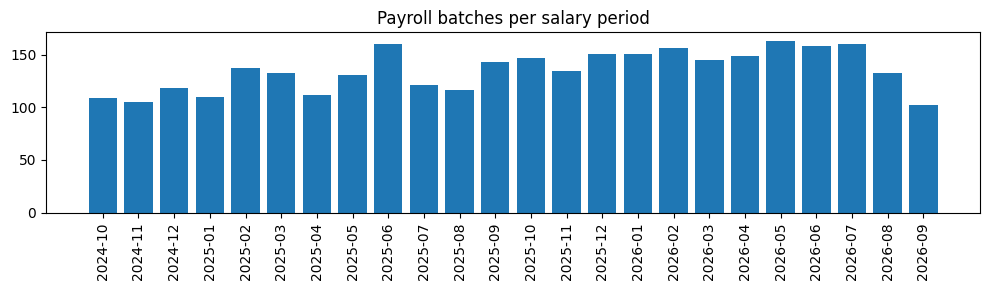

Batches in Sep 2026:             102
Average of the 6 months before:  151


In [9]:
batches_per_period = batch["period"].value_counts().sort_index()

plt.figure(figsize=(10, 3))
plt.bar(batches_per_period.index.strftime("%Y-%m"), batches_per_period.values)
# dates turned into "YYYY-MM" text so each month gets its own labelled bar
plt.xticks(rotation=90)
plt.title("Payroll batches per salary period")
plt.tight_layout()
plt.show()

print("Batches in Sep 2026:            ", batches_per_period.iloc[-1])
print("Average of the 6 months before: ", round(batches_per_period.iloc[-7:-1].mean()))

### 1.5 Join coverage (orphans)

What share of rows find a match when joining?

In [10]:
# 1. Postings (topup) -> Batch (batch) on batchid / topupbatchid
topup_in_batch = topup['batchid'].isin(batch['topupbatchid'])
# check if the same batch ids exist in both tables
topup_to_batch_rate = topup_in_batch.mean()
# take the average of the returned boolean values

print(f"Postings -> Batch coverage: {topup_to_batch_rate:.2%} ({topup_in_batch.sum()} out of {len(topup)} rows matched)")

if not topup_in_batch.all(): # if all elems in the series are True, returns True
    orphans = topup[~topup_in_batch]['batchid'].nunique()
    # Orphan is defined as the Unique ID of the False matches in the series
    # (possible scenario: 500 failed rows all reference the same batch ID)
    print(f"   - Warning: Found {len(topup[~topup_in_batch])} orphan rows pointing to {orphans} unique missing batch IDs")
    # print the total count of unique missing batch IDs (all the NOT true values in the series)

Postings -> Batch coverage: 100.00% (106610 out of 106610 rows matched)


In [11]:
# 2. Postings (topup) -> Employee (emp) on empid
topup_in_emp = topup['empid'].isin(emp['empid'])
topup_to_emp_rate = topup_in_emp.mean()

print(f"Postings -> Employee coverage: {topup_to_emp_rate:.2%} ({topup_in_emp.sum()} out of {len(topup)} rows matched)")

if not topup_in_emp.all():
    print(f"   - Warning: Found {len(topup[~topup_in_emp])} orphan rows pointing to missing employee IDs")

Postings -> Employee coverage: 100.00% (106610 out of 106610 rows matched)


In [12]:
# 3. Employee (emp) -> Sector (sector) on companyid
emp_in_sector = emp['companyid'].isin(sector['companyid'])
emp_to_sector_rate = emp_in_sector.mean()

print(f"Employee -> Sector coverage: {emp_to_sector_rate:.2%} ({emp_in_sector.sum()} out of {len(emp)} rows matched)")

if not emp_in_sector.all():
    print(f"   - Warning: Found {len(emp[~emp_in_sector])} orphan rows pointing to missing company IDs in sector table")

Employee -> Sector coverage: 100.00% (7014 out of 7014 rows matched)


In [13]:
# 4. Card Wallets (card) -> Posting Wallets (topup) on walletid
card_in_topup = card['walletid'].isin(topup['walletid'])
card_to_topup_rate = card_in_topup.mean()

print(f"Card Wallets -> Posting Wallets coverage: {card_to_topup_rate:.2%} ({card_in_topup.sum()} out of {len(card)} rows matched)")

if not card_in_topup.all():
    orphans = card[~card_in_topup]['walletid'].nunique()
    print(f"   - Info: {orphans} unique wallets in card transactions have no records in topup requests")

Card Wallets -> Posting Wallets coverage: 99.38% (119520 out of 120270 rows matched)
   - Info: 82 unique wallets in card transactions have no records in topup requests


### Section 1 summary

**What was done:** loaded and profiled the 7 raw tables (size, types, missing values, keys, date ranges, joins). No data was changed.

| Check | Result |
|---|---|
| Size | 106,610 postings · 3,338 batches · 7,014 employees · 45 companies · 120,270 card rows |
| Keys | all unique, no fully duplicated rows |
| Joins | postings → batch / employee, employee → sector: **100%** · card → postings: 99.38% |
| Statuses | Disbursed 97.00% · Error 2.77% · Pending 0.23% · Rejected 0 |
| Dates | salary periods Oct 2024 – Sep 2026 · postings up to the 8 Oct 2026 extraction |

**What was interesting**
- **94 batches (2.8%) have no salary period**, the biggest data problem found.
- **50 joining dates are placeholders** (1900-01-01 or 2099-12-31).
- **Sep 2026 is incomplete**: 102 batches vs an average of 151 in the six months before (chart).
- Missing values: visa expiry 184, EID expiry 231, card 3-month averages 6,889 rows.

---
## 2. Data Quality Audit & Cleaning Log

**Goal:** find each problem, measure its size, decide a rule, and log it.

Every rule is recorded in a cleaning-log table with columns: `issue | rows_affected | pct_of_total | rule_applied | reason`.

Rows are **flagged** rather than deleted while auditing, so every count stays traceable. The clean table is built once, at the end (2.9).

Subsections:
1. Join everything into one wide postings table
2. Duplicate postings
3. Batches with no salary period
4. Errors, retries and pending postings
5. Amount anomalies
6. Date anomalies
7. Wallet / employee consistency
8. Other issues (split payments, card table)
9. Final cleaning log & clean postings

In [14]:
cleaning_log = []

def log_issue(issue, rows_affected, total, rule, reason):
    cleaning_log.append({
        "issue": issue,
        "rows_affected": rows_affected,
        "pct_of_total": round(100 * rows_affected / total, 2),
        "rule_applied": rule,
        "reason": reason,
    })

### 2.1 Join lookups & build one wide postings table

One row per posting attempt, with its status name, batch info (company, WPS type, salary period) and employee info attached.
All joins are `left` joins, so the row count must stay at 106,610. If it changes, a lookup key is duplicated.

In [15]:
postings = topup.merge(status.rename(columns={"name": "status"}), on="statusid", how="left")
# status name (Disbursed / Error / Pending) instead of an id

postings = postings.merge(
    batch.rename(columns={"topupbatchid": "batchid", "createdon": "batch_createdon"}),
    on="batchid", how="left",
)
# batch columns renamed so they don't clash with the posting's own createdon
# this brings in companyid, typeid, year, month and the period column built in Step 1

postings = postings.merge(
    req_type.rename(columns={"topuprequesttypeid": "typeid", "name": "salary_type"}),
    on="typeid", how="left",
)
# WPS / NONWPS

In [16]:
postings = postings.merge(
    emp[["empid", "walletid", "companyid"]].rename(columns={"walletid": "emp_walletid", "companyid": "emp_companyid"}),
    on="empid", how="left",
)
# employee's wallet and company kept under new names, only to cross-check them in 2.7

postings = postings.merge(sector, on="companyid", how="left")
# sector of the company that ran the batch

print("Rows before joins:", len(topup))
print("Rows after joins: ", len(postings))
TOTAL_POSTINGS = len(postings)

Rows before joins: 106610
Rows after joins:  106610


### 2.2 Duplicate postings

Step 1 showed every `coretopuprequestid` is unique, so duplicates can only be found by business meaning:
**the same employee, in the same batch, posted twice.**

A legitimate salary has exactly one posting per employee per batch (split salaries use *separate* batches, see 2.8).

In [17]:
# count how many postings each employee has inside each batch
per_emp_batch = postings.groupby(["empid", "batchid"]).size()
print(per_emp_batch.value_counts())

1    106202
2       204
Name: count, dtype: int64


In [18]:
# select every posting that shares an employee + batch with another posting
# keep=False marks ALL rows of a duplicate pair as True, so both rows of each pair are kept for inspection
dup_group = postings[postings.duplicated(["empid", "batchid"], keep=False)].sort_values(["empid", "batchid", "createdon"])

pair_summary = dup_group.groupby(["empid", "batchid"]).agg(
    statuses=("status", lambda s: " + ".join(s)),
    # join the duplicate postings' statuses for visibility
    same_amount=("amount", lambda a: a.nunique() == 1),
    # if both postings have 1 unique amount between them, they have the same amount
    gap_minutes=("createdon", lambda c: (c.max() - c.min()).total_seconds() / 60),
    # calculate how far apart the duplicate postings took place
)
print(pair_summary["statuses"].value_counts())
print("\nPairs with identical amount:", pair_summary["same_amount"].sum(), "of", len(pair_summary))
print("\nMinutes between the two postings:")
print(pair_summary["gap_minutes"].describe())

dup_group[["empid", "batchid", "amount", "createdon", "status"]].head(6)

statuses
Disbursed + Disbursed    204
Name: count, dtype: int64

Pairs with identical amount: 202 of 204

Minutes between the two postings:
count    204.000000
mean       0.954739
std        0.569508
min        0.016667
25%        0.466667
50%        0.933333
75%        1.466667
max        1.983333
Name: gap_minutes, dtype: float64


,empid,batchid,amount,createdon,status
1347,70087,80037,2889.29,2025-05-09 21:04:00,Disbursed
1348,70087,80037,2889.29,2025-05-09 21:05:43,Disbursed
2331,70159,80139,985.43,2025-07-28 09:39:00,Disbursed
2332,70159,80139,985.43,2025-07-28 09:40:29,Disbursed
2734,70178,80123,2747.53,2025-12-26 20:16:00,Disbursed
2735,70178,80123,2747.53,2025-12-26 20:16:13,Disbursed


In [19]:
# evidence for "the replayed copy carries seconds": compare the later copy with all other postings
ordered = postings.sort_values(["empid", "batchid", "createdon"])
later_copy = ordered.duplicated(["empid", "batchid"], keep="first")
# same flag as in the next cells: True only for the 2nd (later) posting of a pair
has_seconds = ordered["createdon"].dt.second != 0
# True when the timestamp is not on a whole minute, e.g. 21:05:43

pd.DataFrame({
    "postings": later_copy.value_counts(),
    "with_seconds": has_seconds.groupby(later_copy).sum(),
}).rename(index={False: "all other postings", True: "later copy of a pair"})

,postings,with_seconds
all other postings,106406,0
later copy of a pair,204,203


In [20]:
# the 2 pairs whose amounts differ: which companies are they in?
odd_pairs = pair_summary[~pair_summary["same_amount"]].reset_index()
odd_pairs = odd_pairs.merge(postings[["empid", "companyid"]].drop_duplicates(), on="empid")
odd_pairs

,empid,batchid,statuses,same_amount,gap_minutes,companyid
0,73097,81582,Disbursed + Disbursed,False,0.583333,1028
1,73262,81629,Disbursed + Disbursed,False,1.550000,1027


**What this shows:** every pair is two *Disbursed* postings, at most ~2 minutes apart. Almost all have the identical amount.
The second posting's timestamp also carries seconds (e.x.: `21:05:43`), while normal postings are on whole minutes.
This looks like a system replay of the same posting, not a second payment.

The 2 pairs with different amounts are at companies 1027 and 1028, two of the split-salary employers found in 2.8, where the replayed row has a different amount; they are treated the same way.

**Rule:** within each employee + batch, keep the first posting and flag the later one as a duplicate.

In [21]:
postings = postings.sort_values(["empid", "batchid", "createdon"])
postings["is_duplicate"] = postings.duplicated(["empid", "batchid"], keep="first")
# sorted by createdon so earlier postings are before later postings
# keep="first" -> the earliest posting is kept (False), the replay is flagged (True)

n_dup = postings["is_duplicate"].sum()
print("Duplicate postings flagged:", n_dup)

log_issue(
    "Duplicate posting (same employee + batch, ~2 min apart)",
    n_dup, TOTAL_POSTINGS,
    "Keep earliest posting, drop the later one",
    "Same batch can only pay an employee once; pairs are seconds apart with near-identical amounts -> system replay, would double-count salary",
)

Duplicate postings flagged: 204


### 2.3 Batches with no salary period

94 batches have no `year`/`month`. Labels are built on the salary period, so these postings need a period or must be dropped.

In [22]:
no_period = postings["period"].isna()
print("Batches with no period:  ", batch["period"].isna().sum())
print("Postings on those batches:", no_period.sum(), f"({no_period.mean():.2%} of all postings)")
print(postings.loc[no_period, "status"].value_counts())

Batches with no period:   94
Postings on those batches: 4194 (3.93% of all postings)
status
Disbursed    4081
Error         113
Name: count, dtype: int64


That is ~4% of postings, too many to throw away. Can the period be recovered from the batch's `createdon` date?

The salary period is usually either the **same month** the batch was created (employer pays late in the month) or the **previous month** (employer pays early next month).
Below, *lag* = batch month − salary period month, measured on the batches that **do** have a period, split by the day of month the batch was created.

In [23]:
known = batch.dropna(subset=["period"]).copy()

known["lag_months"] = (known["createdon"].dt.year * 12 + known["createdon"].dt.month) \
                    - (known["period"].dt.year * 12 + known["period"].dt.month)
# months between the salary period and the month the batch was created

known["created_day"] = known["createdon"].dt.day
known["created_late_in_month"] = known["created_day"] >= 20

pd.crosstab(known["lag_months"], known["created_late_in_month"])

created_late_in_month,False,True
lag_months,,
0,5,856
1,2258,109
2,16,0


A clear pattern: batches created **late** in the month mostly pay the **same** month, and batches created **early** in the month mostly pay the **previous** month.

This suggests a rule based on a cut-off day: created on or after the cut-off → same month, otherwise previous month.


Every possible day (1–31) is tested on the batches where the true period is known, and the most accurate one is used.

In [24]:
def infer_period(batch_created, cutoff_day):
    # created on/after cutoff_day -> salary for this month, otherwise salary for last month
    month_start = batch_created.dt.to_period("M").dt.to_timestamp()
    # first day of the month the batch was created in, e.x. 2026-05-25 -> 2026-05-01
    return month_start.where(batch_created.dt.day >= cutoff_day, month_start - pd.DateOffset(months=1))
    # .where(condition, other) keeps month_start where the condition is True,
    # and uses the previous month where it is False

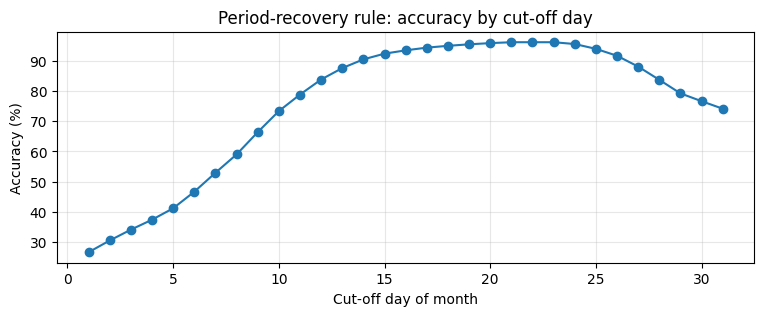

,cutoff_day,accuracy_pct
20,21,96.3
22,23,96.3
21,22,96.3
19,20,96.0
23,24,95.7
18,19,95.6
17,18,95.1
16,17,94.5


In [25]:
results = []
for day in range(1, 32):
    guessed = infer_period(known["createdon"], day)
    # guess the period for every batch whose real period we know
    acc = (guessed == known["period"]).mean()
    # share of guesses that match the real period
    results.append({"cutoff_day": day, "accuracy_pct": round(100 * acc, 1)})

cutoff_test = pd.DataFrame(results)

plt.figure(figsize=(9, 3))
plt.plot(cutoff_test["cutoff_day"], cutoff_test["accuracy_pct"], marker="o")
plt.xlabel("Cut-off day of month")
plt.ylabel("Accuracy (%)")
plt.title("Period-recovery rule: accuracy by cut-off day")
plt.grid(alpha=0.3)
plt.show()

cutoff_test.sort_values("accuracy_pct", ascending=False).head(8)

**Decision:** Choosing 22 as the cutoff day as it falls in the middle of the best range (21-23).

In [26]:
CUTOFF_DAY = 22
accuracy = (infer_period(known["createdon"], CUTOFF_DAY) == known["period"]).mean()
print(f"Chosen cut-off day: {CUTOFF_DAY} -> accuracy {accuracy:.1%} on batches with a known period")

Chosen cut-off day: 22 -> accuracy 96.3% on batches with a known period


In [27]:
# apply the rule only where the period is missing, and remember which rows were filled
postings["period_recovered"] = postings["period"].isna()
postings.loc[postings["period_recovered"], "period"] = infer_period(
    postings.loc[postings["period_recovered"], "batch_createdon"], CUTOFF_DAY
)

print("Postings still without a period:", postings["period"].isna().sum())

log_issue(
    "Batch has no salary period (year/month missing)",
    int(postings["period_recovered"].sum()), TOTAL_POSTINGS,
    f"Infer period from batch createdon: day >= {CUTOFF_DAY} -> same month, else previous month; flag period_recovered",
    f"~4% of postings, too many to drop; cut-off chosen by testing days 1-31, {accuracy:.1%} accurate on batches with a known period",
)

Postings still without a period: 0


### 2.4 Errors, retries and pending postings

**Retry definition:** an Error posting followed **later** by a *Disbursed* posting for the **same employee, same salary period and same amount** (usually in a different batch).

In [28]:
errors = postings[postings["status"] == "Error"]
successes = postings[(postings["status"] == "Disbursed") & ~postings["is_duplicate"]]

retry_match = errors.merge(
    successes[["empid", "period", "amount", "createdon", "coretopuprequestid"]],
    on=["empid", "period", "amount"],
    suffixes=("", "_retry"),
)
# every error paired with every successful posting that has the same employee, period and amount
# two new columns are created from every pair of Error-Success rows: createdon_retry and coretopuprequestid_retry
# createdon_retry: Date/Time of any successful posting with equal features
# coretopuprequestid_retry: ID of the matching posting

retry_match = retry_match[retry_match["createdon_retry"] > retry_match["createdon"]]
"""a retry has to happen after the error, so we check if the
retried record was created after the original attempt record"""
# Now createdon_retry & coretopuprequestid_retry are only made up of valid retries

retried_error_ids = set(retry_match["coretopuprequestid"])
retry_success_ids = set(retry_match["coretopuprequestid_retry"])

print("Error postings:        ", len(errors))
print("Retried Successfully:  ", len(retried_error_ids))
print("Never Retried:         ", len(errors) - len(retried_error_ids))

Error postings:         2956
Retried Successfully:   2464
Never Retried:          492


In [29]:
errors

,coretopuprequestid,empid,walletid,amount,createdon,statusid,batchid,status,companyid,typeid,year,month,batch_createdon,period,salary_type,emp_walletid,emp_companyid,category,is_duplicate,period_recovered
42,5000054,70012,W1000012,3011.42,2026-06-08 16:09:00,2,80008,Error,1045,1,2026.0,5.0,2026-06-08,2026-05-01,WPS,W1000012,1045,Security Services,False,False
47,5000060,70013,W1000013,841.16,2026-03-09 15:06:00,2,80014,Error,1045,1,2026.0,2.0,2026-03-09,2026-02-01,WPS,W1000013,1045,Security Services,False,False
70,5000084,70016,W1000016,3373.98,2026-03-09 14:52:00,2,80014,Error,1045,1,2026.0,2.0,2026-03-09,2026-02-01,WPS,W1000016,1045,Security Services,False,False
162,5000181,70023,W1000023,2378.13,2026-01-07 16:31:00,2,80018,Error,1045,1,2025.0,12.0,2026-01-07,2025-12-01,WPS,W1000023,1045,Security Services,False,False
153,5000172,70023,W1000023,2402.46,2025-05-09 20:46:00,2,80037,Error,1045,1,2025.0,4.0,2025-05-09,2025-04-01,WPS,W1000023,1045,Security Services,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106524,5107484,76997,W1006872,2171.18,2026-08-06 17:21:00,2,83383,Error,1001,1,2026.0,7.0,2026-08-06,2026-07-01,WPS,W1006872,1001,Hospitality,False,False
106533,5107493,76999,W1006874,6283.54,2026-07-08 10:42:00,2,81294,Error,1001,1,2026.0,6.0,2026-07-08,2026-06-01,WPS,W1006874,1001,Hospitality,False,False
106557,5107517,77004,W1006879,1223.61,2026-08-06 16:44:00,2,83383,Error,1001,1,2026.0,7.0,2026-08-06,2026-07-01,WPS,W1006879,1001,Hospitality,False,False
106567,5107527,77006,W1006881,1602.15,2026-07-08 10:46:00,2,81294,Error,1001,1,2026.0,6.0,2026-07-08,2026-06-01,WPS,W1006881,1001,Hospitality,False,False


In [30]:
retry_match

,coretopuprequestid,empid,walletid,amount,createdon,statusid,batchid,status,companyid,typeid,year,month,batch_createdon,period,salary_type,emp_walletid,emp_companyid,category,is_duplicate,period_recovered,createdon_retry,coretopuprequestid_retry
0,5000054,70012,W1000012,3011.42,2026-06-08 16:09:00,2,80008,Error,1045,1,2026.0,5.0,2026-06-08,2026-05-01,WPS,W1000012,1045,Security Services,False,False,2026-06-09 16:09:00,5000055
1,5000060,70013,W1000013,841.16,2026-03-09 15:06:00,2,80014,Error,1045,1,2026.0,2.0,2026-03-09,2026-02-01,WPS,W1000013,1045,Security Services,False,False,2026-03-11 15:06:00,5000061
2,5000084,70016,W1000016,3373.98,2026-03-09 14:52:00,2,80014,Error,1045,1,2026.0,2.0,2026-03-09,2026-02-01,WPS,W1000016,1045,Security Services,False,False,2026-03-12 14:52:00,5000085
3,5000181,70023,W1000023,2378.13,2026-01-07 16:31:00,2,80018,Error,1045,1,2025.0,12.0,2026-01-07,2025-12-01,WPS,W1000023,1045,Security Services,False,False,2026-01-12 16:31:00,5000182
4,5000172,70023,W1000023,2402.46,2025-05-09 20:46:00,2,80037,Error,1045,1,2025.0,4.0,2025-05-09,2025-04-01,WPS,W1000023,1045,Security Services,False,False,2025-05-14 20:46:00,5000173
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2459,5107484,76997,W1006872,2171.18,2026-08-06 17:21:00,2,83383,Error,1001,1,2026.0,7.0,2026-08-06,2026-07-01,WPS,W1006872,1001,Hospitality,False,False,2026-08-08 17:21:00,5107485
2460,5107493,76999,W1006874,6283.54,2026-07-08 10:42:00,2,81294,Error,1001,1,2026.0,6.0,2026-07-08,2026-06-01,WPS,W1006874,1001,Hospitality,False,False,2026-07-12 10:42:00,5107494
2461,5107517,77004,W1006879,1223.61,2026-08-06 16:44:00,2,83383,Error,1001,1,2026.0,7.0,2026-08-06,2026-07-01,WPS,W1006879,1001,Hospitality,False,False,2026-08-10 16:44:00,5107518
2462,5107527,77006,W1006881,1602.15,2026-07-08 10:46:00,2,81294,Error,1001,1,2026.0,6.0,2026-07-08,2026-06-01,WPS,W1006881,1001,Hospitality,False,False,2026-07-09 10:46:00,5107528


In [31]:
retry_delay_days = (retry_match["createdon_retry"] - retry_match["createdon"]).dt.total_seconds() / 86400
# difference in datetime in seconds over the total number of seconds in a day
# --> Difference in Days as a decimal
# dt.days would return a whole number, losing the exact hours

print("Days between error and successful retry:")
print(retry_delay_days.describe().round(1))

Days between error and successful retry:
count    2464.0
mean        3.0
std         1.4
min         1.0
25%         2.0
50%         3.0
75%         4.0
max         5.0
dtype: float64


In [32]:
postings["is_retry"] = postings["coretopuprequestid"].isin(retry_success_ids)
# Used to later calculate Reetry Frequency for a specific employee
"""After we clean the dataset postings, this column will remain to
 let us know a posting was retried before ending up successful"""

n_retried = len(retried_error_ids)
n_unretried = len(errors) - n_retried

# last validation checlk
print("Retried Successfully:  ", n_retried)
print("Never Retried:         ", n_unretried)

log_issue(
    "Error posting later retried successfully",
    n_retried, TOTAL_POSTINGS,
    "Drop the Error row, keep the successful retry (flag is_retry)",
    "Salary did arrive via the retry; keeping the Error row as well would add nothing",
)
log_issue(
    "Error posting never retried",
    n_unretried, TOTAL_POSTINGS,
    "Drop; not a salary arrival",
    "Money never reached the wallet. Spec: posting failures are not credit risk, but an unrecovered failure still means no salary that period",
)

Retried Successfully:   2464
Never Retried:          492


**Pending postings.** Status 3 (*Pending*): when were they created, and did any of them later succeed?

In [33]:
pending = postings[postings["status"] == "Pending"]
# keep only the postings whose status is Pending

print("Pending postings:", len(pending))

print("Salary periods:", pending["period"].dt.strftime("%Y-%m").value_counts().to_dict())
# .dt.strftime("%Y-%m") turns each period date into short text, e.x: 2026-09-01 -> "2026-09"
# .value_counts() counts how many pending postings fall in each period
# .to_dict() prints the result on one line, e.g. {'2026-09': 247}, instead of a multi-line table

print("Created between:", pending["createdon"].min(), "and", pending["createdon"].max())
# earliest and latest pending posting -> shows whether they cluster just before the 8 Oct extraction

pending_matches = pending.merge(successes, on=["empid", "period"], how="inner", suffixes=("", "_success"))
# did any of these pending payments go through anyway?
pending_matches = pending_matches[pending_matches["createdon_success"] > pending_matches["createdon"]]
# only count a success that happened after the pending posting

""" merge(..., how="inner") keeps a pending row only if the same employee
    also has a successful posting for the same salary period"""
""" ["empid"].nunique() then counts how many different employees are left,
    0 means no pending payment was ever completed by a later successful posting """

pending_has_success = pending_matches["empid"].nunique()
print("Pending employees who also have a Disbursed posting that period:", pending_has_success)

Pending postings: 247
Salary periods: {'2026-09': 247}
Created between: 2026-09-19 12:41:00 and 2026-10-08 19:06:00
Pending employees who also have a Disbursed posting that period: 0


All Pending postings are for **Sep 2026**, created in the last ~3 weeks before the 8 Oct extraction.
None of these employees was paid for September some other way, so as of 8 Oct their September salary is **not known yet**: neither paid nor missed.

Sep 2026 is already left unlabeled (assumption A7), so these do not affect any label. They also show why A7 is needed:
if September were labeled, these 247 employees would wrongly be marked as **missed**.

The *Rejected* status (id 4) never appears in the data.

In [34]:
log_issue(
    "Pending posting (all Sep 2026, in flight at extraction)",
    len(pending), TOTAL_POSTINGS,
    "Drop; not counted as an arrival",
    "Outcome unknown at extraction; Sep 2026 is censored anyway (A7), so no label is affected",
)

### 2.5 Amount anomalies

Two checks:
1. Impossible amounts: zero or negative.
2. Unusual amounts **for that person**: a raw amount of 20,000 may be normal for one employee and odd for another, so each month's total is compared with the employee's own median monthly salary.

In [35]:
print("Zero amounts:    ", (postings["amount"] == 0).sum())
print("Negative amounts:", (postings["amount"] < 0).sum())
print()
print(postings["amount"].describe().round(2))

Zero amounts:     0
Negative amounts: 0

count    106610.00
mean       2466.26
std        1251.94
min         217.94
25%        1651.45
50%        2187.15
75%        2949.44
max       20853.11
Name: amount, dtype: float64


In [36]:
# monthly total per employee, using only real arrivals (successful, not duplicated)
real = postings[(postings["status"] == "Disbursed") & ~postings["is_duplicate"]]
monthly = real.groupby(["empid", "period"])["amount"].sum().reset_index()

monthly["usual_amount"] = monthly.groupby("empid")["amount"].transform("median")
monthly["ratio_to_usual"] = monthly["amount"] / monthly["usual_amount"]
# 1.0 = a normal month for that person; 0.5 = half pay; 2.0 = double pay

print(monthly["ratio_to_usual"].describe().round(3))
print()
print("Months at less than half the usual salary:", (monthly["ratio_to_usual"] < 0.5).sum())
print("Months at more than double the usual salary:", (monthly["ratio_to_usual"] > 2).sum())

count    101300.000
mean          1.003
std           0.093
min           0.340
25%           0.979
50%           1.000
75%           1.021
max           2.863
Name: ratio_to_usual, dtype: float64

Months at less than half the usual salary: 213
Months at more than double the usual salary: 264


No zero or negative amounts. How close to the usual salary are most months?

In [37]:
within_10pct = monthly["ratio_to_usual"].between(0.9, 1.1).mean()
print(f"Months within +/-10% of the employee's usual salary: {within_10pct:.1%}")

Months within +/-10% of the employee's usual salary: 97.9%


About **98%** of months are within ±10% of the usual salary. Are the rare months below half or above double the usual pay data errors, or real events?

In [38]:
odd = monthly[(monthly["ratio_to_usual"] < 0.5) | (monthly["ratio_to_usual"] > 2)].copy()
# keep only the unusual months: under half or over double the employee's usual salary

odd["kind"] = np.where(odd["ratio_to_usual"] < 0.5, "low", "high")
# np.where(condition, value_if_true, value_if_false) -> label each odd month "low" or "high"

ratio_lookup = monthly.set_index(["empid", "period"])["ratio_to_usual"]
# turn the monthly table into a lookup: give it (employee, period) -> get back that month's ratio
# e.x: ratio_lookup[(70087, 2025-04-01)] -> 1.02

odd["next_month_ratio"] = [
    ratio_lookup.get((e, p + pd.DateOffset(months=1)))
    for e, p in zip(odd["empid"], odd["period"])
]
# for every odd month, look up the SAME employee's ratio in the FOLLOWING month
#   zip(...) walks through the employee and period columns together, one tuple (e, p) per row
#   p + pd.DateOffset(months=1) -> the next month, e.x: 2025-04-01 -> 2025-05-01
#   .get(...) returns that month's ratio, or None if the employee has no salary that month
# result: a number = salary continued (and how big it was); missing = salary stopped

odd = odd.merge(emp[["empid", "companyid"]], on="empid", how="left")
# attach each employee's company, so we can check whether odd months come from one employer or many

summary = odd.groupby("kind").agg(
    months=("empid", "size"),
    # how many odd months of each kind

    companies=("companyid", "nunique"),
    # how many different companies they come from -> many = not one bad payroll batch

    no_salary_next_month=("next_month_ratio", lambda r: round(r.isna().mean(), 2)),
    # share of odd months with NO salary the following month
    #   r.isna() -> True where next month is missing; .mean() -> share of True values

    median_next_month_ratio=("next_month_ratio", "median"),
    # typical salary size the following month (1.0 = back to normal)
)
summary

,months,companies,no_salary_next_month,median_next_month_ratio
kind,,,,
high,264,40,0.98,0.968465
low,213,33,0.33,0.522243


In [39]:
# are odd months caused by our own cleaning? Compare how often they involve a recovered period (2.3)
# or a split salary (2.8) with how often ALL months do
month_info = real.groupby(["empid", "period"]).agg(
    recovered=("period_recovered", "any"),
    split=("amount", lambda a: len(a) > 1),
).reset_index()
odd_info = odd.merge(month_info, on=["empid", "period"], how="left")

pd.DataFrame({
    "recovered_period_%": [100 * month_info["recovered"].mean(), *(100 * odd_info.groupby("kind")["recovered"].mean())],
    "split_salary_%": [100 * month_info["split"].mean(), *(100 * odd_info.groupby("kind")["split"].mean())],
}, index=["all months", "high months", "low months"]).round(1)

,recovered_period_%,split_salary_%
all months,4.0,1.9
high months,4.9,2.3
low months,1.9,1.9


None of these look like data errors: they are spread across many companies (40 for high months, 33 for low months) and months, and involve recovered periods and split salaries at about their normal rates (table above), so our own cleaning did not create them.

- **High months** (over double the usual salary) are almost always the employee's **last** salary: no salary follows in 98% of cases. This looks like a final settlement (end-of-service pay) just before the salary stops.
- **Low months** (under half the usual salary) signal trouble: a third are followed by **no salary at all** the next month, and the rest by continued pay at **about half the usual amount**. This is *amount drop but not zero* (from README)

Both are kept and counted as paid (A4). Because both are known at the decision date and are strong warning signs, they become features in Step 6.

Note: For features, "usual salary" must use only months **before** the decision date. The ratio above uses each employee's whole history, which is fine for auditing but would leak future information into a model usually.

In [40]:
log_issue(
    "Zero / negative amounts",
    0, TOTAL_POSTINGS,
    "None found; no action",
    "Checked",
)
log_issue(
    "Monthly salary < 50% or > 200% of employee's usual amount",
    int(((monthly["ratio_to_usual"] < 0.5) | (monthly["ratio_to_usual"] > 2)).sum()), len(monthly),
    "Keep; counted as paid, ratio used as a feature",
    "Real events, not errors: high months are usually a final payout before salary stops; low months precede a stop or a sustained drop. Kept as features (A4). % is of employee-months, not postings",
)

### 2.6 Date anomalies

- Postings dated before their salary period starts (paid in advance?)
- Posting date vs batch date consistency
- Postings arriving **more than 30 days after the period ends**: under assumption A2 such a period counts as missed, even though money eventually arrived

In [41]:
postings["period_end"] = postings["period"] + pd.offsets.MonthEnd(0)
# pd.offsets.MonthEnd(0) moves date to last day of current (0) month
# e.x: "2026-05-01" --> "2026-05-31"

postings["days_after_period_end"] = (postings["createdon"] - postings["period_end"]).dt.days
# negative = paid before the month ended; positive = paid after

print("Postings before their period starts:", (postings["createdon"] < postings["period"]).sum())
print("Posting date differs from batch date:", (postings["createdon"].dt.normalize() != postings["batch_createdon"]).sum())
print()
print("Days after period end (successful postings):")
print(real.merge(postings[["coretopuprequestid", "days_after_period_end"]], on="coretopuprequestid")["days_after_period_end"].describe().round(1))

Postings before their period starts: 0
Posting date differs from batch date: 0

Days after period end (successful postings):
count    103203.0
mean          3.1
std           7.1
min         -15.0
25%          -3.0
50%           4.0
75%           8.0
max          40.0
Name: days_after_period_end, dtype: float64


In [42]:
postings["beyond_grace"] = postings["days_after_period_end"] > GRACE_DAYS
late_real = postings["beyond_grace"] & (postings["status"] == "Disbursed") & ~postings["is_duplicate"]

print(f"Successful postings arriving more than {GRACE_DAYS} days after period end:", late_real.sum())
batch_lag_months = (postings["batch_createdon"].dt.year * 12 + postings["batch_createdon"].dt.month) \
                 - (postings["period"].dt.year * 12 + postings["period"].dt.month)
# same 'lag' idea as in 2.3: months between the salary period and the payroll run

print("Of these, on payrolls run 2 months after the period:", (late_real & (batch_lag_months == 2)).sum())

Successful postings arriving more than 30 days after period end: 110
Of these, on payrolls run 2 months after the period: 107


No postings before their period, and every posting is dated the same day as its batch, so the two date sources agree.

A small number of real salaries arrive beyond the 30-day grace window, mostly from payrolls run two months after the period.
They stay in the data with a `beyond_grace` flag; Step 4 applies my assumption A2 and counts such a period as missed.

In [43]:
log_issue(
    f"Salary arrived more than {GRACE_DAYS} days after period end",
    int(late_real.sum()), TOTAL_POSTINGS,
    "Keep posting, flag beyond_grace; period labelled missed in Step 4",
    "Agreed definition (A2): missed = nothing within 30 days after period end",
)

### 2.7 Wallet / employee consistency

- Does the posting's wallet match the employee table's wallet?
- Does the batch's company match the employee's company?
- Does any employee post to more than one wallet, or any wallet receive salary from more than one employment?
- Employee joining dates (`doj`): placeholders, and joining dates after the first salary

In [44]:
print("Posting wallet != employee wallet:  ", (postings["walletid"] != postings["emp_walletid"]).sum())
print("Batch company != employee company:  ", (postings["companyid"] != postings["emp_companyid"]).sum())
print("Employees posting to >1 wallet:     ", (postings.groupby("empid")["walletid"].nunique() > 1).sum())

emps_per_wallet = emp.groupby("walletid")["empid"].nunique()
print("Wallets with >1 employment record:  ", (emps_per_wallet > 1).sum())

Posting wallet != employee wallet:   0
Batch company != employee company:   0
Employees posting to >1 wallet:      0
Wallets with >1 employment record:   124


Wallets with more than one employment record are **employer switches**: the person moved jobs and kept the same wallet.
That is continuity, not an error (assumption A3). Check that two employers never pay the same wallet for the same period, which *would* be suspicious:

In [45]:
wallet_period_employers = real.groupby(["walletid", "period"])["empid"].nunique()
print("Wallet-periods paid by more than one employment:", (wallet_period_employers > 1).sum())

Wallet-periods paid by more than one employment: 0


In [46]:
log_issue(
    "Wallet has more than one employment (employer switch)",
    int((emps_per_wallet > 1).sum()), emp["walletid"].nunique(),
    "Keep; continuity is per wallet; switch count becomes a feature",
    "Confirmed by reviewer (A3); no overlapping pay periods found. % is of wallets",
)

**Joining dates.** Step 1 found 50 values before 1950 or after the extraction date.

In [47]:
placeholder_doj = (emp["doj"] < "1950-01-01") | (emp["doj"] > EXTRACTION_DATE)
print(emp.loc[placeholder_doj, "doj"].value_counts())

doj
2099-12-31    25
1900-01-01    25
Name: count, dtype: int64


In [48]:
emp["doj"] = emp["doj"].mask(placeholder_doj)
# .mask() replaces the flagged values with NaT (missing date)

log_issue(
    "Placeholder joining date (1900-01-01 / 2099-12-31)",
    int(placeholder_doj.sum()), len(emp),
    "Set doj to missing",
    "System default values, not real dates; would give tenure of 126 years or negative. % is of employees",
)

In [49]:
# joining date compared with the employee's first successful salary
first_salary = real.groupby("empid")["createdon"].min().dt.normalize()
doj_vs_first = (emp.set_index("empid")["doj"] - first_salary).dt.days
# positive = the employee 'joined' after already being paid

print("Employees whose doj is after their first salary:", (doj_vs_first > 0).sum())
print("Days after first salary:", doj_vs_first[doj_vs_first > 0].value_counts().sort_index().to_dict())

Employees whose doj is after their first salary: 32
Days after first salary: {1.0: 16, 2.0: 12, 3.0: 2, 4.0: 1, 5.0: 1}


In [50]:
log_issue(
    "Joining date a few days after first salary",
    int((doj_vs_first > 0).sum()), len(emp),
    "Keep as is",
    "Only 1-5 days off; consistent with onboarding/record timing, not a data error worth changing",
)

### 2.8 Other issues

**Split salaries.** After removing duplicates, some employees still have two successful postings for the same salary period, in **different** batches.

In [51]:
postings_per_period = real.groupby(["empid", "period"]).size()
print("Successful postings per employee-period:")
print(postings_per_period.value_counts())

multi = real.set_index(["empid", "period"]).loc[postings_per_period[postings_per_period > 1].index].reset_index()
print("\nCompanies involved:")
print(multi.groupby("companyid")["empid"].nunique().sort_values(ascending=False).head())

Successful postings per employee-period:
1    99417
2     1863
3       20
Name: count, dtype: int64

Companies involved:
companyid
1027    183
1028    146
1018     31
1016      1
Name: empid, dtype: int64


In [52]:
# one example employee from a split-paying company
example_emp = multi["empid"].iloc[0]
real[real["empid"] == example_emp].sort_values("createdon")[["batchid", "period", "amount", "createdon", "salary_type"]].tail(8)

,batchid,period,amount,createdon,salary_type
11887,80571,2026-04-01,1467.57,2026-04-28 13:22:00,WPS
11888,80572,2026-05-01,629.73,2026-05-25 20:14:00,NONWPS
11889,80573,2026-05-01,865.77,2026-06-04 20:14:00,NONWPS
11890,80574,2026-06-01,1470.29,2026-06-21 09:30:00,NONWPS
11891,80575,2026-07-01,631.92,2026-07-27 09:38:00,NONWPS
11892,80576,2026-07-01,794.19,2026-08-05 09:38:00,NONWPS
11893,80577,2026-08-01,1481.65,2026-08-26 13:38:00,NONWPS
11894,80578,2026-09-01,1482.03,2026-09-28 16:52:00,NONWPS


These come almost entirely from a few companies that pay salary **in two parts** about 1–2 weeks apart.
Each part is roughly half the usual amount, and the two add up to a normal monthly salary.

**Rule:** both postings are real. They are **summed** into one monthly amount in Step 3 (not dropped).

In [53]:
log_issue(
    "Salary split into 2+ postings in one period (different batches)",
    int(postings_per_period[postings_per_period > 1].sum()), TOTAL_POSTINGS,
    "Keep all; sum per wallet-period in Step 3",
    "Concentrated in a few employers that pay in two parts; parts add up to a normal salary",
)

**Card table.** Step 1 found 6,889 rows with missing 3-month averages. Check whether they are each wallet's first month:

In [54]:
card = card.sort_values(["walletid", "txn_month"])
card["month_number"] = card.groupby("walletid").cumcount() + 1
# 1 = the wallet's first month in the card table

print("Missing 3-month average by wallet month number:")
print(card.loc[card["txn_count_3m_avg"].isna(), "month_number"].value_counts())

Missing 3-month average by wallet month number:
month_number
1    6889
Name: count, dtype: int64


In [55]:
log_issue(
    "Card 3-month averages missing",
    int(card["txn_count_3m_avg"].isna().sum()), len(card),
    "Leave as missing",
    "All in each wallet's first month: no history to average yet. % is of card rows",
)

**Snapshot fields.** `empstatus`, `visaexpiry` and `eidexpirydate` describe each employee as of Oct 2026, not as of each decision date.

In [56]:
print(emp["empstatus"].value_counts())
print()
print("Missing visa expiry:", emp["visaexpiry"].isna().sum())
print("Missing EID expiry: ", emp["eidexpirydate"].isna().sum())

empstatus
card activated    5609
inactive          1155
kyc pending        146
card blocked       104
Name: count, dtype: int64

Missing visa expiry: 184
Missing EID expiry:  231


In [57]:
log_issue(
    "empstatus is an Oct 2026 snapshot",
    len(emp), len(emp),
    "Exclude from features",
    "Reflects the outcome (e.g. 'inactive' after salary stopped) -> leakage (A9)",
)
log_issue(
    "Visa / EID expiry missing",
    int(emp["visaexpiry"].isna().sum()), len(emp),
    "Leave missing; use expiry features only with snapshot caveat",
    "Snapshot field; may reflect renewals after the decision date (A9)",
)

### 2.9 Final cleaning log & clean postings

The clean table keeps only real salary arrivals:
- status = Disbursed
- not a duplicate

Errors and Pending rows are dropped. Successful retries, recovered periods, split salaries and late arrivals are kept and flagged.

In [58]:
log_df = pd.DataFrame(cleaning_log)
log_df

,issue,rows_affected,pct_of_total,rule_applied,reason
0,"Duplicate posting (same employee + batch, ~2 m...",204,0.19,"Keep earliest posting, drop the later one",Same batch can only pay an employee once; pair...
1,Batch has no salary period (year/month missing),4194,3.93,Infer period from batch createdon: day >= 22 -...,"~4% of postings, too many to drop; cut-off cho..."
2,Error posting later retried successfully,2464,2.31,"Drop the Error row, keep the successful retry ...",Salary did arrive via the retry; keeping the E...
3,Error posting never retried,492,0.46,Drop; not a salary arrival,Money never reached the wallet. Spec: posting ...
4,"Pending posting (all Sep 2026, in flight at ex...",247,0.23,Drop; not counted as an arrival,Outcome unknown at extraction; Sep 2026 is cen...
5,Zero / negative amounts,0,0.00,None found; no action,Checked
6,Monthly salary < 50% or > 200% of employee's u...,477,0.47,"Keep; counted as paid, ratio used as a feature","Real events, not errors: high months are usual..."
7,Salary arrived more than 30 days after period end,110,0.10,"Keep posting, flag beyond_grace; period labell...",Agreed definition (A2): missed = nothing withi...
8,Wallet has more than one employment (employer ...,124,1.80,Keep; continuity is per wallet; switch count b...,Confirmed by reviewer (A3); no overlapping pay...
9,Placeholder joining date (1900-01-01 / 2099-12...,50,0.71,Set doj to missing,"System default values, not real dates; would g..."


In [59]:
clean_postings = postings[(postings["status"] == "Disbursed") & ~postings["is_duplicate"]].copy()

clean_postings = clean_postings[[
    "coretopuprequestid", "empid", "walletid", "companyid", "category", "batchid",
    "salary_type", "period", "period_recovered", "amount", "createdon",
    "days_after_period_end", "beyond_grace", "is_retry",
]].sort_values(["walletid", "period", "createdon"])
# keep only the columns later steps need, ordered by wallet and time

print("Postings before cleaning:", TOTAL_POSTINGS)
print("Postings after cleaning: ", len(clean_postings))
print("Removed:                 ", TOTAL_POSTINGS - len(clean_postings))
clean_postings.head()

Postings before cleaning: 106610
Postings after cleaning:  103203
Removed:                  3407


,coretopuprequestid,empid,walletid,companyid,category,batchid,salary_type,period,period_recovered,amount,createdon,days_after_period_end,beyond_grace,is_retry
0,5000002,70002,W1000002,1045,Security Services,80002,WPS,2026-08-01,False,2645.29,2026-09-08 10:54:00,8,False,False
1,5000004,70003,W1000003,1045,Security Services,80003,WPS,2026-07-01,False,2345.79,2026-08-07 11:24:00,7,False,False
2,5000005,70003,W1000003,1045,Security Services,80004,NONWPS,2026-08-01,False,2157.02,2026-09-08 10:18:00,8,False,False
3,5000007,70004,W1000004,1045,Security Services,80005,WPS,2026-06-01,False,3057.84,2026-07-09 12:06:00,9,False,False
4,5000008,70004,W1000004,1045,Security Services,80003,WPS,2026-07-01,False,2984.14,2026-08-07 11:42:00,7,False,False


### Section 2 summary

**What was done:** checked the postings for 9 kinds of problems, measured each one and set a rule for it (cleaning log, 2.9).

| Issue | Size | Rule |
|---|---|---|
| Duplicate postings (≤ 2 min apart) | 204 | drop later copy |
| No salary period | 4,194 postings (3.9%) | recover from batch date, cut-off day 22 (96.3% accurate) |
| Errors retried successfully | 2,464 of 2,956 (83%) | keep the retry |
| Errors never retried | 492 | drop (no salary) |
| Pending (all Sep 2026) | 247 | drop |
| Paid > 30 days after month end | 110 | keep, month counts as missed |
| Split salaries | 1,883 wallet-months | keep, add up |
| Placeholder joining dates | 50 | set to missing |

**Result:** 106,610 → **103,203** clean postings.

**What was interesting**
- **Salary months over 2× usual are almost always the last salary** (98% have no salary next month).
- **Months under ½ usual are often followed by a stop** (33% have no salary next month).
- Both looked like errors at first but are real warning signs, so they were kept.

---
# Part II — Building the Dataset
Sections 3–5: turn clean postings into monthly salaries, paid/missed labels and decision rows.

## 3. Monthly Salary Table (wallet × salary period)

**Goal:** one row per wallet per salary period that received salary.

Columns: `walletid, period, total_amount, n_postings, first_arrival_date, days_after_period_end, paid_within_grace, companyid, is_wps, had_retry, period_recovered`.

Also verify employers actually pay monthly (check gaps between periods per company) before relying on it.

### 3.1 Build the monthly table

**Why this step exists.** Every later step asks one question: *did salary arrive for wallet W in salary month M?*
`clean_postings` can't answer that directly: it has one row per **posting**, and one month can have several postings
(split salaries, 2.8), while one wallet can appear under several employees (employer switches, 2.7).
This step changes the grain to **one row per wallet per salary month**.

**Choices made here:**
- Group by **wallet** (A3) and by salary **period**, not posting date (A1).
- **Add up** the amounts of split salaries.
- Keep the **earliest** arrival per month: the 30-day grace rule (A2) asks whether money arrived in time.
- Keep months paid **after** the grace window as rows, flagged `paid_within_grace = False`: the money is real, but the month counts as missed.

In [60]:
clean_postings.head(3)

,coretopuprequestid,empid,walletid,companyid,category,batchid,salary_type,period,period_recovered,amount,createdon,days_after_period_end,beyond_grace,is_retry
0,5000002,70002,W1000002,1045,Security Services,80002,WPS,2026-08-01,False,2645.29,2026-09-08 10:54:00,8,False,False
1,5000004,70003,W1000003,1045,Security Services,80003,WPS,2026-07-01,False,2345.79,2026-08-07 11:24:00,7,False,False
2,5000005,70003,W1000003,1045,Security Services,80004,NONWPS,2026-08-01,False,2157.02,2026-09-08 10:18:00,8,False,False


In [61]:
monthly_salary = clean_postings.groupby(["walletid", "period"]).agg (
    total_amount = ("amount", "sum"),
    n_postings = ("amount", "size"),
    first_arrival_date = ("createdon", "min"),
    days_after_period_end = ("days_after_period_end", "min"),
    companyid = ("companyid", "first"),
    category = ("category", "first"),
    is_wps = ("salary_type", lambda s: (s == "WPS").any()),
    # # True if at least one posting in the month was WPS
    had_retry = ("is_retry", "any"),
    # True if any posting that month was retried (is_retry=True)
    period_recovered = ("period_recovered", "any")
    # True if any posting that month was recovered (period_recovered=True)
).reset_index()
# reset_index() turns walletid and period back into normal columns

In [62]:
monthly_salary["paid_within_grace"] = monthly_salary["days_after_period_end"] <= GRACE_DAYS
# the first payment arrived within 30 days of the period end -> counts as paid in Step 4

In [63]:
# qiuck checks to see if any data loss occurred:

assert len(monthly_salary) == clean_postings[["walletid", "period"]].drop_duplicates().shape[0]
# unique (walletid, period) pairs in clean_postings -> no month lost or duplicated
assert np.isclose(monthly_salary["total_amount"].sum(), clean_postings["amount"].sum())
# no money lost or double counted: the monthly totals add up to the same amount as all postings
# np.isclose instead of == because adding up decimals can differ by tiny rounding errors
assert (clean_postings.groupby(["walletid", "period"])["companyid"].nunique() == 1).all()
# exactly one unique company per wallet-month
print("All checks passed")

All checks passed


In [64]:
monthly_salary

,walletid,period,total_amount,n_postings,first_arrival_date,days_after_period_end,companyid,category,is_wps,had_retry,period_recovered,paid_within_grace
0,W1000002,2026-08-01,2645.29,1,2026-09-08 10:54:00,8,1045,Security Services,True,False,False,True
1,W1000003,2026-07-01,2345.79,1,2026-08-07 11:24:00,7,1045,Security Services,True,False,False,True
2,W1000003,2026-08-01,2157.02,1,2026-09-08 10:18:00,8,1045,Security Services,False,False,False,True
3,W1000004,2026-06-01,3057.84,1,2026-07-09 12:06:00,9,1045,Security Services,True,False,False,True
4,W1000004,2026-07-01,2984.14,1,2026-08-07 11:42:00,7,1045,Security Services,True,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...
101295,W1006888,2026-09-01,3066.09,1,2026-10-04 15:33:00,4,1001,Hospitality,True,False,False,True
101296,W1006889,2026-05-01,3152.64,1,2026-06-07 15:59:00,7,1001,Hospitality,True,False,False,True
101297,W1006889,2026-06-01,3151.08,1,2026-07-08 10:13:00,8,1001,Hospitality,True,False,False,True
101298,W1006889,2026-07-01,3177.14,1,2026-08-06 17:04:00,6,1001,Hospitality,True,False,False,True


### 3.2 Payroll frequency check

Do employers really pay once per salary month? For each company, list the salary months it paid and look for gaps (months with no payroll at all) or months with unusually many batches.
A company-wide gap is an **employer disruption** signal, so we keep the result for Step 4.2 and Step 10.

In [65]:
monthly_salary[["companyid", "period", "walletid", "period_recovered"]]

,companyid,period,walletid,period_recovered
0,1045,2026-08-01,W1000002,False
1,1045,2026-07-01,W1000003,False
2,1045,2026-08-01,W1000003,False
3,1045,2026-06-01,W1000004,False
4,1045,2026-07-01,W1000004,False
...,...,...,...,...
101295,1001,2026-09-01,W1006888,False
101296,1001,2026-05-01,W1006889,False
101297,1001,2026-06-01,W1006889,False
101298,1001,2026-07-01,W1006889,False


In [66]:
company_months = monthly_salary.groupby(["companyid", "period"]).agg(
    headcount=("walletid", "nunique"),
    # number of different wallets paid by this company in this month
    any_recovered=("period_recovered", "any"),
    # True if any of this month's salaries had their period filled in by the cut-off rule (2.3)
).reset_index()

company_months

,companyid,period,headcount,any_recovered
0,1001,2026-05-01,103,False
1,1001,2026-06-01,107,False
2,1001,2026-07-01,103,False
3,1001,2026-08-01,101,False
4,1001,2026-09-01,100,False
...,...,...,...,...
903,1045,2026-04-01,88,True
904,1045,2026-05-01,88,False
905,1045,2026-06-01,85,False
906,1045,2026-07-01,85,False


In [67]:
gaps = []
for company, months in company_months.groupby("companyid"):
    # months = this company's rows only, one per month it ran payroll
    all_months = pd.date_range(months["period"].min(), months["period"].max(), freq="MS")
    # every month from the company's first to its last payroll; "MS" = month start, matching period
    missing = all_months.difference(months["period"])
    # months in the full range that the company never paid
    for month in missing:
        gaps.append({"companyid": company, "gap_month": month})

gaps = pd.DataFrame(gaps, columns=["companyid", "gap_month"])
# columns given explicitly so the table still has headers if no gaps are found
print("Months with no payroll inside a company's history:", len(gaps))
gaps

Months with no payroll inside a company's history: 0


,companyid,gap_month


In [68]:
company_months = company_months.sort_values(["companyid", "period"])

company_months["prev_headcount"] = company_months.groupby("companyid")["headcount"].shift(1)
company_months["next_headcount"] = company_months.groupby("companyid")["headcount"].shift(-1)
# .shift(1) moves each value down one row -> the previous month's headcount on the current row
# .shift(-1) moves values up one row -> the next month's headcount
# doing it inside groupby("companyid") stops values leaking from one company into the next
# (a company's first month has no previous month -> NaN; its last month has no next month -> NaN)

company_months["headcount_change"] = company_months["headcount"] / company_months["prev_headcount"]
# 1.0 = same headcount as last month; 0.5 = half as many people paid

drops = company_months[company_months["headcount_change"] < 0.7].copy()
# months where headcount fell by more than 30% compared with the month before

print("Sharp headcount drops (> 30%):", len(drops), "in", drops["companyid"].nunique(), "companies")
print("...in a month with recovered periods:", drops["any_recovered"].sum())
drops[["companyid", "period", "prev_headcount", "headcount", "next_headcount", "headcount_change", "any_recovered"]].round(2)

Sharp headcount drops (> 30%): 11 in 7 companies
...in a month with recovered periods: 1


,companyid,period,prev_headcount,headcount,next_headcount,headcount_change,any_recovered
163,1008,2026-01-01,60.0,31,4.0,0.52,False
164,1008,2026-02-01,31.0,4,NaN,0.13,False
263,1013,2025-07-01,88.0,36,8.0,0.41,False
264,1013,2025-08-01,36.0,8,NaN,0.22,False
335,1017,2026-02-01,128.0,75,37.0,0.59,False
336,1017,2026-03-01,75.0,37,8.0,0.49,True
337,1017,2026-04-01,37.0,8,NaN,0.22,False
491,1025,2025-06-01,56.0,21,50.0,0.38,False
519,1026,2025-10-01,66.0,17,59.0,0.26,False
608,1031,2026-03-01,625.0,148,498.0,0.24,False


In [69]:
# for drops that bounced back: next month's headcount as a share of the headcount before the drop
dips = drops[drops["next_headcount"].notna() & (drops["next_headcount"] > drops["headcount"])].copy()
dips["recovered_to_%"] = (100 * dips["next_headcount"] / dips["prev_headcount"]).round(0)
dips[["companyid", "period", "prev_headcount", "headcount", "next_headcount", "recovered_to_%"]]

,companyid,period,prev_headcount,headcount,next_headcount,recovered_to_%
491,1025,2025-06-01,56.0,21,50.0,89.0
519,1026,2025-10-01,66.0,17,59.0,89.0
608,1031,2026-03-01,625.0,148,498.0,80.0
768,1040,2025-01-01,152.0,49,119.0,78.0


In [70]:
LAST_LABELED_MONTH = pd.Timestamp("2026-08-01")
# last month with a reliable outcome (Sep 2026 is censored, A7)

company_span = company_months.groupby("companyid")["period"].agg(
    first_month="min",
    last_month="max",
    months_paid="count",
)

stopped = company_span[company_span["last_month"] < LAST_LABELED_MONTH]
# companies whose payroll ends before Aug 2026 -> they stopped paying through the platform entirely

print("Companies that stopped paying before Aug 2026:", len(stopped))
print("Companies that joined after Oct 2024:         ", (company_span["first_month"] > company_span["first_month"].min()).sum())
stopped

Companies that stopped paying before Aug 2026: 3
Companies that joined after Oct 2024:          12


,first_month,last_month,months_paid
companyid,,,
1008,2024-10-01,2026-02-01,17
1013,2025-01-01,2025-08-01,8
1017,2024-10-01,2026-04-01,19


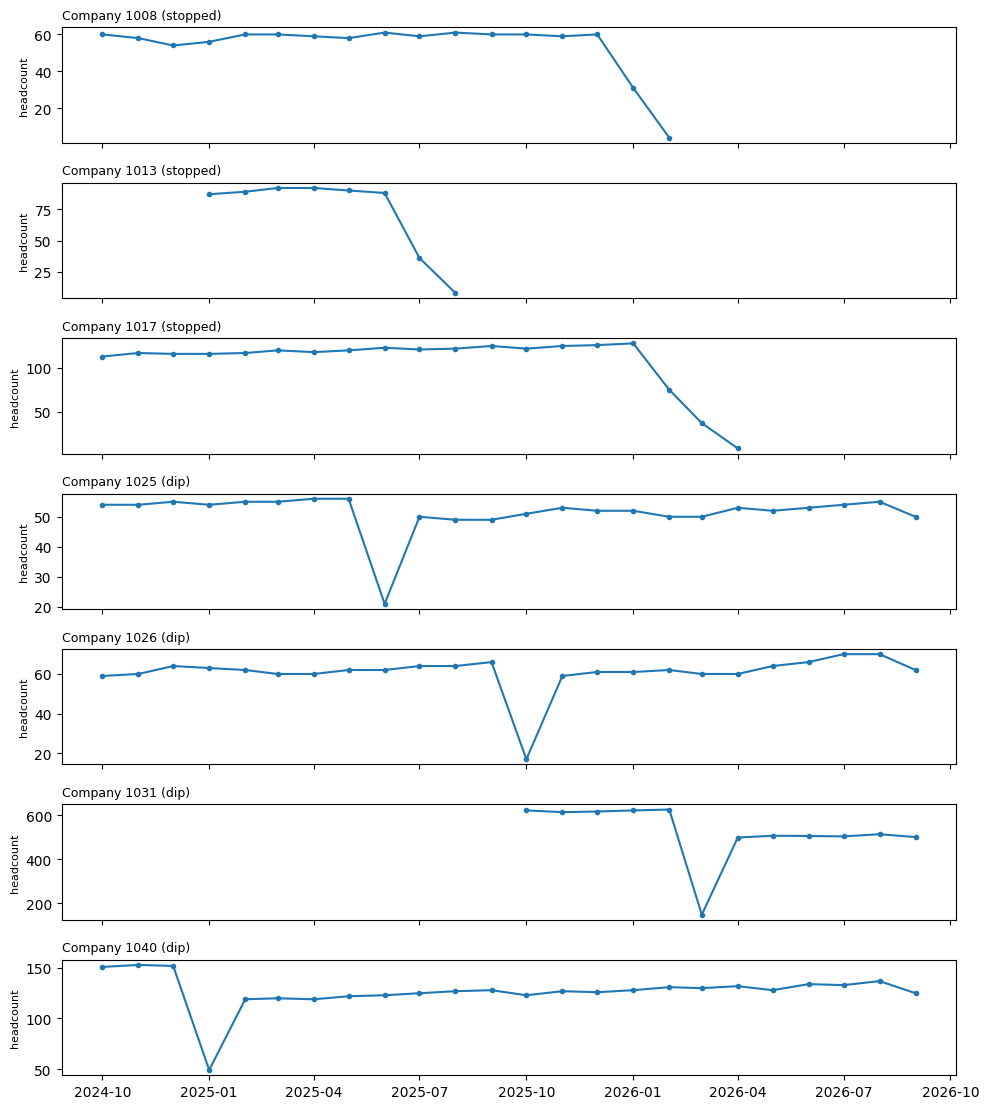

In [71]:
flagged = drops["companyid"].unique()

fig, axes = plt.subplots(len(flagged), 1, figsize=(10, 1.6 * len(flagged)), sharex=True)
# one small chart per flagged company, stacked vertically, sharing the same time axis
for ax, company in zip(axes, flagged):
    history = company_months[company_months["companyid"] == company]
    ax.plot(history["period"], history["headcount"], marker="o", markersize=3)
    label = "stopped" if company in stopped.index else "dip"
    ax.set_title(f"Company {company} ({label})", fontsize=9, loc="left")
    ax.set_ylabel("headcount", fontsize=8)
plt.tight_layout()
plt.show()

### Section 3 summary

**What was done:** combined postings into one row per wallet per salary month, then checked every employer's payroll month by month.

| Check | Result |
|---|---|
| Wallet-months | 101,300 (row count, total amount and one company per month all checked) |
| Companies | 45, no months without payroll inside any company's history |
| Sharp headcount drops (> 30%) | 11, in 7 companies |

**What was interesting**
- **Wind-down then stop** (1008, 1013, 1017): headcount falls over 2–3 months, then payroll ends (e.g. 1017: 128 → 75 → 37 → 8).
- **One-month dip then partial recovery** (1025, 1026, 1031, 1040): most staff unpaid for a month, then pay returns at 78–89% of the old headcount.

---
## 4. Labels & Employer Completeness

**Goal:** create the paid/missed label for every month a wallet was expected to be paid.

- For each wallet, list every salary month from its **first** observed salary through **Aug 2026**.
- **Paid** = money arrived within 30 days after the month ended (`paid_within_grace`); **missed** otherwise, including months with no row in `monthly_salary`.
- Sep 2026 is censored (A7).

**Timing convention used from here on (A10):** a decision about month *t* is made once month *t*'s outcome is known,
i.e. at the end of its grace window. Anything a decision uses must come from salary months **≤ t** (and card months ≤ t).

### 4.1 Wallet × month grid with labels

`monthly_salary` only has rows for months where money arrived. A missed month leaves **no row at all**, so the misses have to be created:
build the full list of months each wallet *should* have been paid, then see which ones have a salary.

In [72]:
LAST_LABELED_MONTH = pd.Timestamp("2026-08-01")
# last month with a reliable outcome (Sep 2026 is censored, A7)

first_month = monthly_salary.groupby("walletid")["period"].min()
# each wallet's first salary month = when we start expecting salary from it

first_month = first_month[first_month <= LAST_LABELED_MONTH]
# wallets whose first salary is Sep 2026 have no labeled month yet -> left out

print("Wallets with at least one labeled month:", len(first_month))
print("Wallets left out (first salary in Sep 2026):", monthly_salary["walletid"].nunique() - len(first_month))

Wallets with at least one labeled month: 6736
Wallets left out (first salary in Sep 2026): 65


In [73]:
grid = pd.DataFrame({
    "walletid": first_month.index,
    "period": [pd.date_range(start, LAST_LABELED_MONTH, freq="MS") for start in first_month],
})
# one row per wallet, holding the LIST of every month from its first salary to Aug 2026

grid = grid.explode("period").reset_index(drop=True)
grid["period"] = pd.to_datetime(grid["period"])
# .explode() turns each list into separate rows: one row per wallet per month

print("Grid rows (wallet-months expected to be paid):", len(grid))
grid.head()

Grid rows (wallet-months expected to be paid): 116257


,walletid,period
0,W1000002,2026-08-01
1,W1000003,2026-07-01
2,W1000003,2026-08-01
3,W1000004,2026-06-01
4,W1000004,2026-07-01


In [74]:
grid = grid.merge(
    monthly_salary[["walletid", "period", "total_amount", "days_after_period_end", "paid_within_grace",
                    "companyid", "category", "is_wps", "had_retry", "period_recovered"]],
    on=["walletid", "period"],
    how="left",
)
# left join keeps every expected month; months with no salary get NaN in the salary columns

grid["paid"] = grid["paid_within_grace"].eq(True).astype(int)
# paid = a salary row exists AND it arrived within the grace window
# no row -> NaN -> filled with False -> 0 (missed)
grid["missed"] = 1 - grid["paid"]

print("Paid months:  ", grid["paid"].sum())
print("Missed months:", grid["missed"].sum(), f"({grid['missed'].mean():.1%})")

Paid months:   97164
Missed months: 19093 (16.4%)


In [75]:
grid = grid.sort_values(["walletid", "period"]).reset_index(drop=True)

grid["company_known"] = grid["companyid"].notna()
grid["companyid"] = grid.groupby("walletid")["companyid"].ffill()
grid["category"] = grid.groupby("walletid")["category"].ffill()
# a missed month has no salary row, so no company. ffill() ("forward fill") copies the last known
# company down into the missed months -> a missed month is attributed to the wallet's most recent employer.
# This only uses earlier months, so it never looks into the future.

grid["companyid"] = grid["companyid"].astype(int)
grid[["walletid", "period", "companyid", "total_amount", "paid", "missed", "company_known"]].head(8)

,walletid,period,companyid,total_amount,paid,missed,company_known
0,W1000002,2026-08-01,1045,2645.29,1,0,True
1,W1000003,2026-07-01,1045,2345.79,1,0,True
2,W1000003,2026-08-01,1045,2157.02,1,0,True
3,W1000004,2026-06-01,1045,3057.84,1,0,True
4,W1000004,2026-07-01,1045,2984.14,1,0,True
5,W1000004,2026-08-01,1045,NaN,0,1,False
6,W1000005,2026-05-01,1045,2347.63,1,0,True
7,W1000005,2026-06-01,1045,2381.09,1,0,True


**Hand check.** Look at a few real wallets: an employer switcher, a split-salary payer and a wallet with a month paid beyond the grace window.

In [76]:
switcher = monthly_salary.groupby("walletid")["companyid"].nunique().idxmax()
# a wallet paid by more than one company (employer switch)
print("Employer switcher:", switcher)
print(grid.loc[grid["walletid"] == switcher, ["period", "companyid", "total_amount", "paid", "missed"]]
      .tail(8).to_string(index=False))

Employer switcher: W1000057
    period  companyid  total_amount  paid  missed
2026-01-01       1045       2389.77     1       0
2026-02-01       1045       2251.96     1       0
2026-03-01       1045       2380.07     1       0
2026-04-01       1045       3334.90     1       0
2026-05-01       1045           NaN     0       1
2026-06-01       1045           NaN     0       1
2026-07-01       1044       1784.52     1       0
2026-08-01       1044       1898.46     1       0


In [77]:
late = monthly_salary.loc[~monthly_salary["paid_within_grace"]].iloc[0]
# the first wallet-month whose salary arrived after the grace window

around = grid[(grid["walletid"] == late["walletid"])
              & (grid["period"].between(late["period"] - pd.DateOffset(months=2), late["period"] + pd.DateOffset(months=2)))]
# that wallet's months from 2 months before to 2 months after the late month
print("Late payment:", late["walletid"], late["period"].strftime("%Y-%m"))
print(around[["period", "total_amount", "days_after_period_end", "paid", "missed"]].to_string(index=False))

Late payment: W1000901 2024-11
    period  total_amount  days_after_period_end  paid  missed
2024-10-01       3000.75                    6.0     1       0
2024-11-01       3090.02                   31.0     0       1
2024-12-01       3125.16                    9.0     1       0
2025-01-01           NaN                    NaN     0       1


### 4.2 Employer completeness

For each company and month: of the employees the company **paid last month**, what share were paid this month?

"Expected employees" uses only the previous month, so it never relies on future information.
A low share is the employer-disruption signal found in 3.2 (e.g. company 1031: 625 → 148).

In [78]:
grid["prev_paid"] = grid.groupby("walletid")["paid"].shift(1)
grid["prev_company"] = grid.groupby("walletid")["companyid"].shift(1)
# .shift(1) inside each wallet puts LAST month's values on this month's row

expected = grid[grid["prev_paid"] == 1]
# wallet-months where the wallet was paid last month -> these employees were "expected" this month

employer_months = expected.groupby(["prev_company", "period"]).agg(
    expected_employees=("walletid", "size"),
    paid_employees=("paid", "sum"),
).reset_index().rename(columns={"prev_company": "companyid"})
employer_months["companyid"] = employer_months["companyid"].astype(int)

employer_months["share_paid"] = employer_months["paid_employees"] / employer_months["expected_employees"]
# 1.0 = everyone paid last month was paid again; 0.25 = three out of four were not

print("Company-months:", len(employer_months))
print(employer_months["share_paid"].describe().round(3))

Company-months: 830
count    830.000
mean       0.952
std        0.110
min        0.000
25%        0.956
50%        0.971
75%        0.984
max        1.000
Name: share_paid, dtype: float64


In [79]:
low_share = employer_months[employer_months["share_paid"] < 0.7].sort_values("share_paid")
print("Company-months where under 70% of expected employees were paid:", len(low_share))
low_share.round(3)

Company-months where under 70% of expected employees were paid: 16


,companyid,period,expected_employees,paid_employees,share_paid
135,1008,2024-11-01,60,0,0.000
150,1008,2026-03-01,4,0,0.000
243,1013,2025-09-01,8,0,0.000
271,1016,2024-12-01,36,0,0.000
309,1017,2026-05-01,8,0,0.000
149,1008,2026-02-01,31,3,0.097
308,1017,2026-04-01,37,4,0.108
242,1013,2025-08-01,36,7,0.194
557,1031,2026-03-01,625,146,0.234
476,1026,2025-10-01,66,16,0.242


In [80]:
# were these employees really unpaid, or paid too late? count any salary that arrived (even after the grace window)
arrivals = monthly_salary.groupby(["companyid", "period"]).agg(
    arrived_any_time=("walletid", "size"),
    median_days_late=("days_after_period_end", "median"),
).reset_index()

low_share.merge(arrivals, on=["companyid", "period"], how="left")[
    ["companyid", "period", "expected_employees", "paid_employees", "arrived_any_time", "median_days_late"]
]
# arrived_any_time >> paid_employees with median_days_late > 30 -> the payroll ran, but after the grace window

,companyid,period,expected_employees,paid_employees,arrived_any_time,median_days_late
0,1008,2024-11-01,60,0,58.0,35.0
1,1008,2026-03-01,4,0,NaN,NaN
2,1013,2025-09-01,8,0,NaN,NaN
3,1016,2024-12-01,36,0,34.0,32.0
4,1017,2026-05-01,8,0,NaN,NaN
5,1008,2026-02-01,31,3,4.0,9.0
6,1017,2026-04-01,37,4,8.0,1.0
7,1013,2025-08-01,36,7,8.0,5.0
8,1031,2026-03-01,625,146,148.0,-15.0
9,1026,2025-10-01,66,16,17.0,1.0


### 4.3 Sanity check: miss rate by month

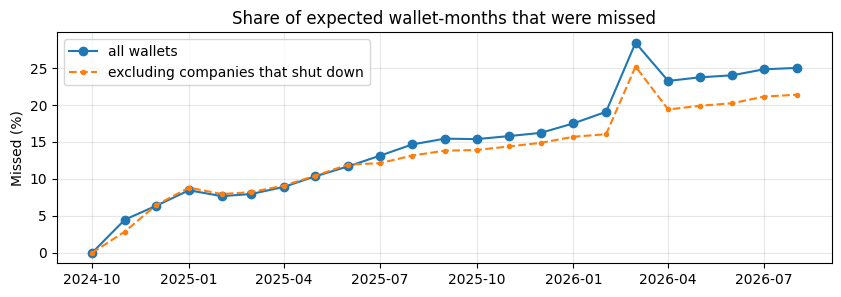

In [81]:
miss_rate = grid.groupby("period")["missed"].mean()
miss_rate_excl_stopped = grid[~grid["companyid"].isin(stopped.index)].groupby("period")["missed"].mean()
# second line leaves out the 3 companies that shut down (3.2), to see how much they drive the trend

plt.figure(figsize=(10, 3))
plt.plot(miss_rate.index, 100 * miss_rate.values, marker="o", label="all wallets")
plt.plot(miss_rate_excl_stopped.index, 100 * miss_rate_excl_stopped.values, marker=".", linestyle="--",
         label="excluding companies that shut down")
plt.ylabel("Missed (%)")
plt.title("Share of expected wallet-months that were missed")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Why does the miss rate keep rising? Once a wallet stops being paid, **every** later month up to Aug 2026 counts as missed, so stopped wallets pile up over time.
That is fine: Step 5 stops following a decision at its first miss (A6), so these trailing months are never used as separate outcomes.
The useful view is the **new-miss rate**: of the wallets paid last month, how many were missed this month?

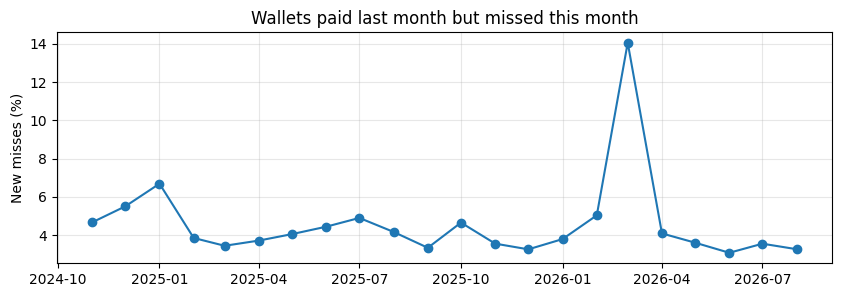

Median new-miss rate: 3.95%

Worst months:
period
2026-03-01    14.0%
2025-01-01     6.7%
2024-12-01     5.5%
2026-02-01     5.0%
2025-07-01     4.9%
Name: paid, dtype: object


In [82]:
new_miss_rate = 1 - expected.groupby("period")["paid"].mean()
# among wallets paid last month, the share missed this month -> the rate a decision actually faces

plt.figure(figsize=(10, 3))
plt.plot(new_miss_rate.index, 100 * new_miss_rate.values, marker="o")
plt.ylabel("New misses (%)")
plt.title("Wallets paid last month but missed this month")
plt.grid(alpha=0.3)
plt.show()

print(f"Median new-miss rate: {new_miss_rate.median():.2%}")
print("\nWorst months:")
print((100 * new_miss_rate.sort_values(ascending=False).head(5)).round(1).astype(str) + "%")

In [83]:
spike_months = new_miss_rate.sort_values(ascending=False).head(3).index
# the three worst months: which companies drive them?
for month in spike_months:
    top = (expected[(expected["period"] == month) & (expected["paid"] == 0)]
           .groupby("prev_company").size().sort_values(ascending=False).head(3))
    print(month.strftime("%Y-%m"), "-> new misses by company:", top.to_dict())

2026-03 -> new misses by company: {1031.0: 479, 1017.0: 47, 1004.0: 20}
2025-01 -> new misses by company: {1040.0: 103, 1004.0: 19, 1042.0: 12}
2024-12 -> new misses by company: {1016.0: 36, 1004.0: 21, 1042.0: 14}


In [84]:
# do recovered periods (2.3) create fake misses? A wrongly guessed month would leave a missed month next to it.
paid_rows = grid[grid["paid"] == 1].copy()
paid_rows["next_missed"] = grid.groupby("walletid")["missed"].shift(-1).loc[paid_rows.index]
# was the month AFTER this paid month missed?

print(paid_rows.groupby("period_recovered")["next_missed"].mean().round(3)
      .rename({False: "normal period", True: "recovered period"}))

period_recovered
normal period       0.046
recovered period    0.037
Name: next_missed, dtype: float64


### Section 4 summary

**What was done:** listed every month each wallet should have been paid, labelled each one paid or missed, and measured how many of each employer's staff were paid.

| Result | Value |
|---|---|
| Wallets / expected wallet-months | 6,736 / 116,257 |
| Missed wallet-months | 19,093 (16.4%) |
| New-miss rate (paid last month, missed this month) | median **3.95%** per month |
| Company-months with < 70% of staff paid | 16 |

**What was interesting**
- **Misses spike with single employers:** Mar 2026 14.0% (company 1031: 479 new misses), Jan 2025 6.7% (1040), Dec 2024 5.5% (1016).
- **Two whole-company payrolls were paid too late** (median 32–35 days after month end), so all their staff count as missed.
- **Recovered periods don't create fake misses**: the next month is missed 3.7% of the time vs 4.6% normally.

---
## 5. Modeling Dataset (Person-Period)

**Goal:** build the discrete-time survival dataset.

- **Decision point:** each month *t* in which a wallet was paid (this is when a loan could be considered).
- For each decision point, create one row per month ahead, *k* = 1…6. Target = `missed` in month *t+k*.
- **Stop at the first miss** (A6): once a month is missed, the later months don't matter for that decision.
- **Drop rows whose target month is after Aug 2026** (outcome unknown, A7).

Resulting grain: `walletid × decision_period × k`.

**Why one row per month ahead?** The model learns the *hazard*: the chance of a miss in month *k*, given no miss before it.
Multiplying the "no miss" chances together gives M1…M6 (Step 8), and they can never contradict each other (M3 can't be above M2).

### 5.1 Decision points

In [85]:
decisions = grid.loc[grid["paid"] == 1, ["walletid", "period"]].rename(columns={"period": "decision_period"})
decisions = decisions[decisions["decision_period"] < LAST_LABELED_MONTH]
# a decision in Aug 2026 would need Sep 2026 as its first outcome, which is censored -> last decision month is Jul 2026

print("Decision points:", len(decisions))
print("Wallets:        ", decisions["walletid"].nunique())

Decision points: 92113
Wallets:         6641


### 5.2 One row per month ahead (k = 1…6)

In [86]:
horizons = pd.DataFrame({"k": range(1, MAX_HORIZON + 1)})

person_period = decisions.merge(horizons, how="cross")
# how="cross" pairs every decision with every k -> each decision appears 6 times (k = 1..6)

person_period["target_period"] = (person_period["decision_period"].dt.to_period("M") + person_period["k"]).dt.to_timestamp()
# the month this row is about: decision month + k months
# .dt.to_period("M") turns 2026-03-01 into the month "2026-03", which supports "+ k months" directly;
# .dt.to_timestamp() turns it back into 2026-03-01 style dates so it matches the grid's period column

person_period = person_period[person_period["target_period"] <= LAST_LABELED_MONTH]
# drop rows whose outcome month is Sep 2026 or later (unknown)

print("Rows before stopping at the first miss:", len(person_period))

Rows before stopping at the first miss: 478976


In [87]:
person_period = person_period.merge(
    grid[["walletid", "period", "missed"]].rename(columns={"period": "target_period"}),
    on=["walletid", "target_period"],
    how="left",
)
# attach the label of the target month from the grid

assert person_period["missed"].notna().all()
# every target month is inside the grid (the grid runs without gaps from first salary to Aug 2026)

In [88]:
person_period = person_period.sort_values(["walletid", "decision_period", "k"]).reset_index(drop=True)

misses_so_far = person_period.groupby(["walletid", "decision_period"])["missed"].cumsum()
# running count of misses from k=1 up to and including this row, within each decision
misses_before = misses_so_far - person_period["missed"]
# misses BEFORE this row (subtract this row's own value)

person_period = person_period[misses_before == 0].reset_index(drop=True)
# keep a row only if no earlier month of the same decision was missed (A6)
# -> the first miss is kept (it is the event), everything after it is dropped

print("Rows after stopping at the first miss:", len(person_period))
person_period.head(8)

Rows after stopping at the first miss: 429059


,walletid,decision_period,k,target_period,missed
0,W1000003,2026-07-01,1,2026-08-01,0
1,W1000004,2026-06-01,1,2026-07-01,0
2,W1000004,2026-06-01,2,2026-08-01,1
3,W1000004,2026-07-01,1,2026-08-01,1
4,W1000005,2026-05-01,1,2026-06-01,0
5,W1000005,2026-05-01,2,2026-07-01,0
6,W1000005,2026-05-01,3,2026-08-01,0
7,W1000005,2026-06-01,1,2026-07-01,0


### 5.3 Sanity checks

In [89]:
by_k = person_period.groupby("k").agg(rows=("missed", "size"), miss_rate=("missed", "mean"))
by_k["miss_rate"] = (100 * by_k["miss_rate"]).round(2)
print("Rows and hazard (miss rate) per month ahead:")
by_k
# rows shrink as k grows for two reasons: later decisions run out of labeled months, and decisions stop at a miss

Rows and hazard (miss rate) per month ahead:


,rows,miss_rate
k,,
1,92113,4.59
2,83059,4.59
3,74599,4.59
4,66705,4.52
5,59471,4.53
6,53112,3.86


In [90]:
assert person_period.groupby(["walletid", "decision_period"])["missed"].sum().max() <= 1
# each decision has at most one miss (its event)

assert (person_period["target_period"] > person_period["decision_period"]).all()
# every outcome is strictly after its decision

example = person_period.loc[person_period["missed"] == 1, ["walletid", "decision_period"]].iloc[0]
person_period[(person_period["walletid"] == example["walletid"])
              & (person_period["decision_period"] == example["decision_period"])]
# one decision that ends in a miss: rows run k = 1, 2, ... and stop at the missed month

,walletid,decision_period,k,target_period,missed
1,W1000004,2026-06-01,1,2026-07-01,0
2,W1000004,2026-06-01,2,2026-08-01,1


### 5.4 Decision-level outcomes (for evaluation in Step 9)

The model is trained on the person-period rows, but M1…M6 are judged per decision:
*did salary arrive in every month from t+1 to t+k?* (A5). This table holds that answer for each decision and horizon.

In [91]:
last_k_observed = person_period.groupby(["walletid", "decision_period"])["k"].max()
# how far each decision can be followed (until its first miss or until Aug 2026)
first_miss_k = person_period[person_period["missed"] == 1].groupby(["walletid", "decision_period"])["k"].min()
# the month ahead in which the first miss happened (missing if never missed)

outcomes = pd.DataFrame({"last_k_observed": last_k_observed, "first_miss_k": first_miss_k}).reset_index()

for k in range(1, MAX_HORIZON + 1):
    survived = outcomes["first_miss_k"].isna() | (outcomes["first_miss_k"] > k)
    # survived to k = no miss at all, or the first miss came after month k
    known = (outcomes["last_k_observed"] >= k) | (outcomes["first_miss_k"] <= k)
    # the answer is known if we followed the decision to month k, or it already failed earlier
    outcomes[f"survived_M{k}"] = survived.astype(float).where(known)
    # where(known) -> NaN when the answer is unknown (decision too recent)

print("Decisions with a known answer, and share that survived, per horizon:")
pd.DataFrame({
    "known": outcomes[[f"survived_M{k}" for k in range(1, 7)]].notna().sum(),
    "survived_%": (100 * outcomes[[f"survived_M{k}" for k in range(1, 7)]].mean()).round(1),
})

Decisions with a known answer, and share that survived, per horizon:


,known,survived_%
survived_M1,92113,95.4
survived_M2,87284,90.8
survived_M3,82638,86.1
survived_M4,78166,81.5
survived_M5,73945,76.8
survived_M6,70282,72.7


### Section 5 summary

**What was done:** turned every paid month into a decision point and created one row per month ahead (k = 1…6), stopping at the first miss.

| Result | Value |
|---|---|
| Decision points | 92,113 (6,641 wallets) |
| Person-period rows | 429,059 |
| Chance of a miss each month (hazard) | ~4.6% (k = 1–5), 3.9% (k = 6) |
| Salary kept arriving for… | M1 95.4% · M3 86.1% · **M6 72.7%** |

**What was interesting**
- **About a quarter of decisions see salary stop within six months.**